### Assignment 1

**Name**: Christian Ulrik Niekrenz

**Student ID**: 21435375

First we load in relevant packages.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

### Data generation

In [170]:
# Generate synthetic data
n = 1000 # samples
np.random.seed(42) # For reproducibility
x = np.linspace(-10, 10, n)
a, b, c = 2, 3, -1 # True parameters. We will try to recover these parameters
# True model + noise. 
y_true = a * x ** 2 + b * x + c
y = y_true + np.random.normal(0, 25, len(x)) 

I added a bit more noise, then what was originally in the code.

Text(0, 0.5, 'y')

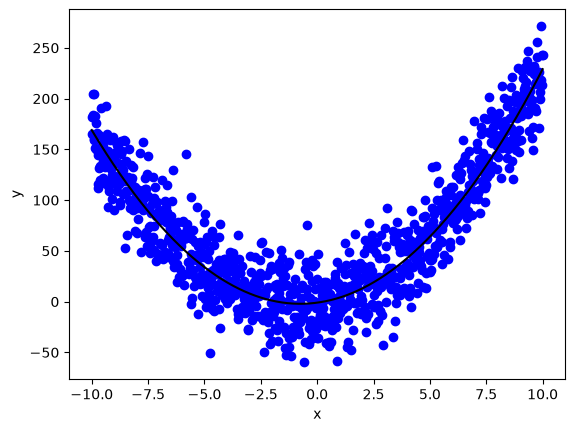

In [111]:
fix, ax = plt.subplots()
ax.scatter(x,y,color = 'blue')
ax.plot(x, y_true, color = 'black')
ax.set_xlabel('x')
ax.set_ylabel('y')

### Implementation of multiple linear regression using Gradient descent

First let's create the design matrix

In [171]:
X = np.column_stack([np.ones(n), x, x**2])
X.shape

(1000, 3)

Then we implement the mini-batch gradient descent, in this case we sample with replacement.

In [114]:
def SGD(y, X, eta = 0.00005, conv_thres = 10**(-7), max_iter = 50000, batch_n = 200, init = None):
    (n,p) = X.shape
    iter = 0
    w = np.zeros(p)
    w_list = w[np.newaxis, :]
    err = lambda w: sum((y - X @ w)**2)/(2*n)
    prv_err = 0
    curr_err = err(w)
    err_list = []
    while abs(prv_err - curr_err) > conv_thres:
        if iter == max_iter:
            print("Maximum iterations reached, did not converge.")
            break
        i_s = np.random.randint(0, n, size=batch_n) 
        prv_err = curr_err
        dw = X[i_s, :].T @ (y[i_s] - X[i_s, :] @ w) / batch_n
        w = w + eta * dw
        w_list = np.vstack([w_list, w[np.newaxis, :]])
        curr_err = err(w)
        err_list.append(curr_err)
        iter += 1
    return [w, err_list, w_list]

In [191]:
sgd_estimator = SGD(y, X, max_iter=500,batch_n=200)
sgd_estimator[0]

Maximum iterations reached, did not converge.


array([0.02529361, 1.77763238, 2.00114921])

Lets take a look at how the parameters change with each iteration.

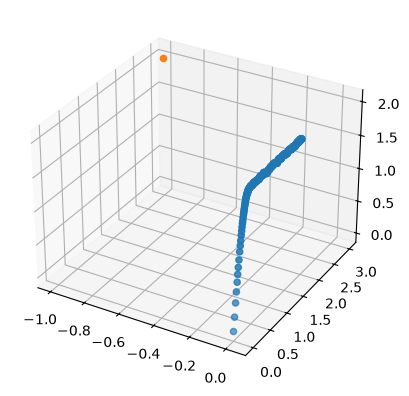

In [173]:
w_list = sgd_estimator[2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(w_list[:,0], w_list[:, 1], w_list[:, 2])
ax.scatter([c], [b], [a])

We would expect the MSE error to be (after doing a lot of linear algebra):
\begin{align*}
\frac{1}{2}\mathbb{E}[MSE] = \frac{\sigma^2}{2}\left(1-\frac{p}{n} \right)=\frac{\sigma^2}{2}\left(1-\frac{3}{1000}\right)=311.5
\end{align*}

Her we try to compare the convergence of the training error, with different batch-size. 

In [200]:
# Using different batch size
sgd_estimator_10 = SGD(y, X, max_iter=500, batch_n=10)
sgd_estimator_1 = SGD(y, X, max_iter=500, batch_n=1)

Maximum iterations reached, did not converge.
Maximum iterations reached, did not converge.


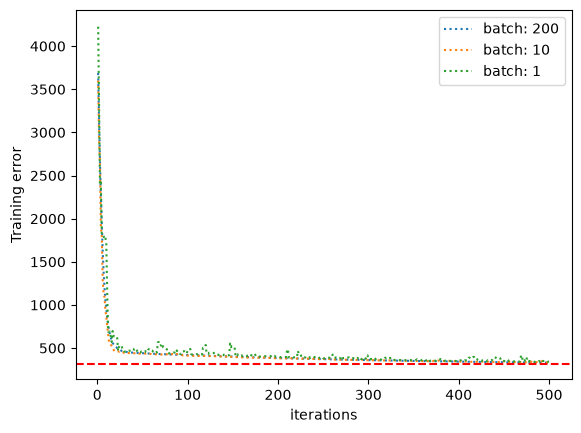

In [201]:
err_list = sgd_estimator[1]

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(err_list) + 1), err_list, linestyle='dotted', label="batch: 200")
ax.plot(np.arange(1, len(err_list) + 1), sgd_estimator_10[1], linestyle='dotted', label="batch: 10")
ax.plot(np.arange(1, len(err_list) + 1), sgd_estimator_1[1], linestyle='dotted', label="batch: 1")
ax.set_xlabel('iterations')
ax.set_ylabel('Training error')
ax.axhline(y=311.5, color='red', linestyle='--')
ax.legend()

It is clear that they all converge to the expected MSE, but there is sone volatility in the training error, when the batch-size is small (n=1) in this case. Which makes sense.

### Data example

First we will load in the data.

In [118]:
avgtemp_df = pd.read_csv(
    r"..\data\avgTropSST_187001-202402.txt",
    sep=r"\s+",
    header=None,
    skiprows=1,
    names=["days_since_1870", "avg_sst_K"]
)

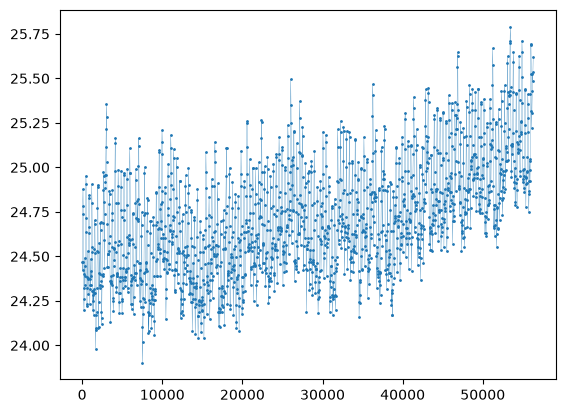

In [165]:
avgtemp_np = avgtemp_df.to_numpy()
fig, ax = plt.subplots()
ax.scatter(avgtemp_df.days_since_1870, avgtemp_df.avg_sst_K, s = 1)
ax.plot(avgtemp_df.days_since_1870, avgtemp_df.avg_sst_K, linewidth = 0.2)

It is hard to get a clear view of the pattern in the data, since there is a lot of data over a long period.

### Zoom in

(0.0, 5000.0)

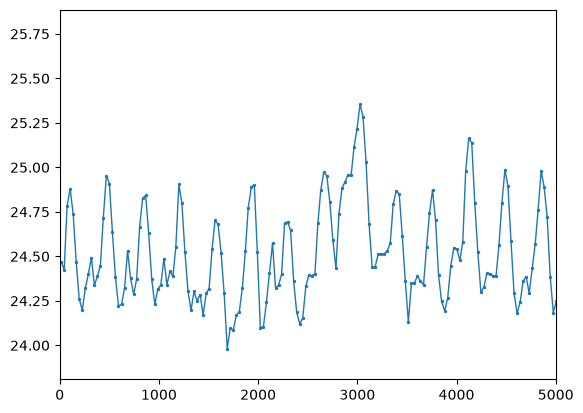

In [169]:
avgtemp_np = avgtemp_df.to_numpy()
fig, ax = plt.subplots()
ax.scatter(avgtemp_df.days_since_1870, avgtemp_df.avg_sst_K, s=2)
ax.plot(avgtemp_df.days_since_1870, avgtemp_df.avg_sst_K, linewidth = 1)
ax.set_xlim(0,5000)

Over a short time horisen it is clear that we have a yearly cycle.

### Create data

I will just create the model matrix for both models, and run the two models alongside each other.

In [121]:
# Lets create design matrix for our models 
P = 365.25

t_at = avgtemp_np[:, 0]
y_at = avgtemp_np[:, 1]
X_at_1 = np.column_stack(
    [
        np.ones(avgtemp_np.shape[0]),
        np.sin(2*np.pi*t_at/P),
        np.cos(2*np.pi*t_at/P)
    ]
)

### Split data into train/test 70/30

In [ ]:
n = X_at_1.shape[0]
id_list = np.arange(n)
idx_train = np.random.choice(id_list, size = int(0.7*n), replace=False)
idx_test = np.delete(id_list, idx_train)

t_mean, t_std = t_at[idx_train].mean(), t_at[idx_train].std()
t_z = (t_at - t_mean) / t_std

X_at_2 = np.column_stack([X_at_1, t_z])

We have to standardize our covariate in the linear term, since it has a much larger range compared to the target variable.

In [123]:
f_1 = lambda w,t: w[0] + w[1]*np.sin(2*np.pi*t/P) + w[2]*np.cos(2*np.pi*t/P)
f_2 = lambda w,t: f_1(w[[0,1,2]], t) + w[3]*(t - t_mean)/t_std

In [124]:
sgd_at_1 = SGD(y_at[idx_train], X_at_1[idx_train], max_iter=5000, eta=0.03)
sgd_at_2 = SGD(y_at[idx_train], X_at_2[idx_train], max_iter=5000, eta=0.03)

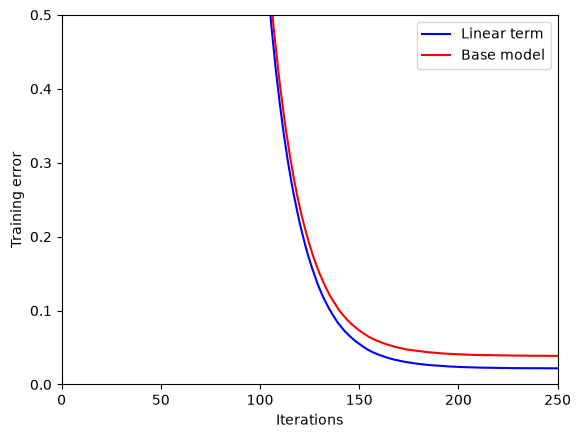

In [143]:
fig, ax = plt.subplots()
ax.plot(np.arange(len(sgd_at_2[1])), sgd_at_2[1], color = 'blue', label = 'Linear term')
ax.plot(np.arange(len(sgd_at_1[1])), sgd_at_1[1], color = 'red', label = 'Base model')
ax.set_xlim(0,250)
ax.set_ylim(0,0.5)
ax.set_xlabel('Iterations')
ax.set_ylabel('Training error')
ax.legend()

Here we can see the training error, as a function of iterations. Based on only the training data, we cannot say anything about which model is best, since a more complex model will have lower training error no matter what.

### Residuals

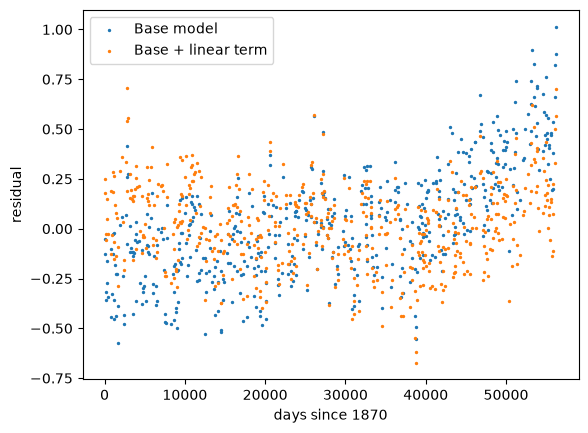

In [203]:
fig, ax = plt.subplots()
ax.scatter(avgtemp_np[idx_test,0], y_at[idx_test] - X_at_1[idx_test] @ sgd_at_1[0], s=2, label = 'Base model')
ax.scatter(avgtemp_np[idx_test,0], y_at[idx_test] - X_at_2[idx_test] @ sgd_at_2[0], s=2, label = 'Base + linear term')
ax.set_xlabel('days since 1870')
ax.set_ylabel('residual')
ax.legend()

So looking at the residuals above, for the base model, there is a clear trend in the residuals and for larger x-values the mean is not 0. It looks a bit better for the model with the linear term.

Lets plot our models over the real data.

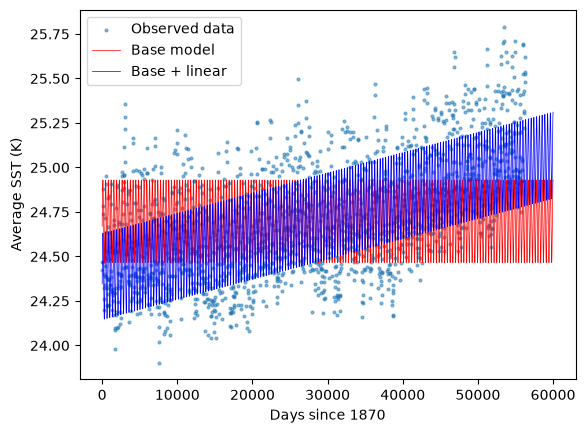

In [204]:
t_grid = np.linspace(0, 60000, 100000)

fig, ax = plt.subplots()

ax.scatter(t_at, y_at, s=4, alpha=0.5, label="Observed data")
ax.plot(
    t_grid,
    f_1(sgd_at_1[0], t_grid),
    color="red",
    label="Base model",
    linewidth = 0.5
)
ax.plot(
    t_grid,
    f_2(sgd_at_2[0], t_grid),
    color="blue",
    label="Base + linear",
    linewidth = 0.5
)
ax.set_xlabel("Days since 1870")
ax.set_ylabel("Average SST (K)")
ax.legend()

Here it is clear why the linear term helps, since there is a positive drift in the data, and the linear term can capture this effect. This is also what we see in the residuals.

### Test error

In [130]:
MSE = lambda y,x: 1/len(x)*sum((y-x)**2)

In [131]:
MSE_1_test = MSE(y_at[idx_test], X_at_1[idx_test] @ sgd_at_1[0])
MSE_2_test = MSE(y_at[idx_test], X_at_2[idx_test] @ sgd_at_2[0])
MSE_1_train = MSE(y_at[idx_train], X_at_1[idx_train] @ sgd_at_1[0])
MSE_2_train = MSE(y_at[idx_train], X_at_2[idx_train] @ sgd_at_2[0])

print(MSE_1_test, MSE_1_train, MSE_2_test, MSE_2_train)

0.07795029221308641 0.07717378892548886 0.043870250542150255 0.043101872329571335


There is no sign of overfitting, since for both models, the training and test error are very close. But the model with the linear terms, has a significantly lower test-error, so this seems like a better model for the data.

### Global warming?

Since the model with the linear term is better, and the coefficient for the linear part is positive, there is some evidence here for a rising trend in the global temperature. 